#### Section E - Data Visualisation

**E1 — Comparing collision frequency and severity**       
Our research question:    
Which posted speed-limit categories have the most recorded collisions, and which have the highest proportion of fatal or serious collisions?

In [ ]:
# Step:1- Prepare the data
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Group the data by speed limit
speed_plot_data = (master_collision.groupby("speed_limit").agg(
    Total_collision =("collision_severity", 'size'),
    Total_collision_KSI=("collision_KSI", 'sum')).reset_index())

#Calculate KSI percentage

speed_plot_data["KSI_percentage"] = (speed_plot_data["Total_collision_KSI"]/speed_plot_data["Total_collision"]) * 100 

# Display
print(speed_plot_data.round(2))

   speed_limit  Total_collision  Total_collision_KSI  KSI_percentage
0           20            20045                 4481           22.35
1           30            49673                12323           24.81
2           40             8886                 2423           27.27
3           50             4612                 1364           29.58
4           60            12709                 4623           36.38
5           70             5600                 1430           25.54


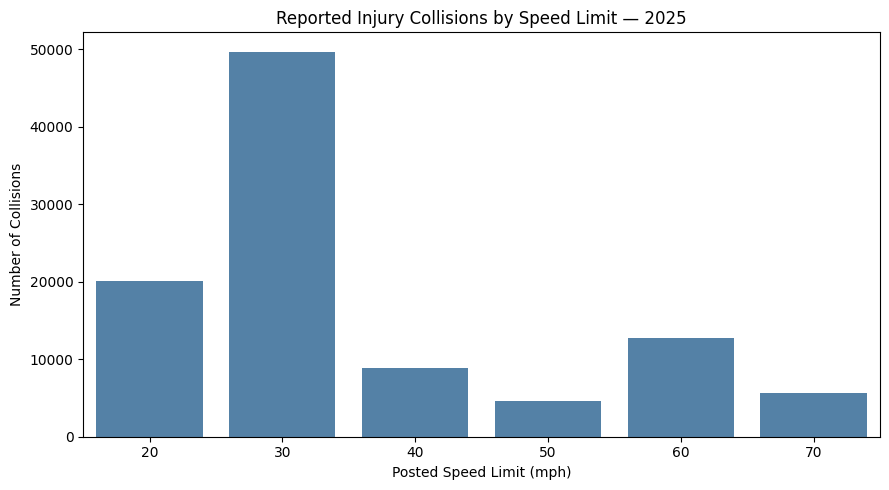

In [ ]:
#Steps: 2- The collision-frequency chart
plt.figure(figsize=(9, 5))

sns.barplot(
    data=speed_plot_data,
    x="speed_limit",
    y="Total_collision",
    color="steelblue"
)

plt.title("Reported Injury Collisions by Speed Limit — 2025")
plt.xlabel("Posted Speed Limit (mph)")
plt.ylabel("Number of Collisions")

plt.tight_layout()
plt.show()

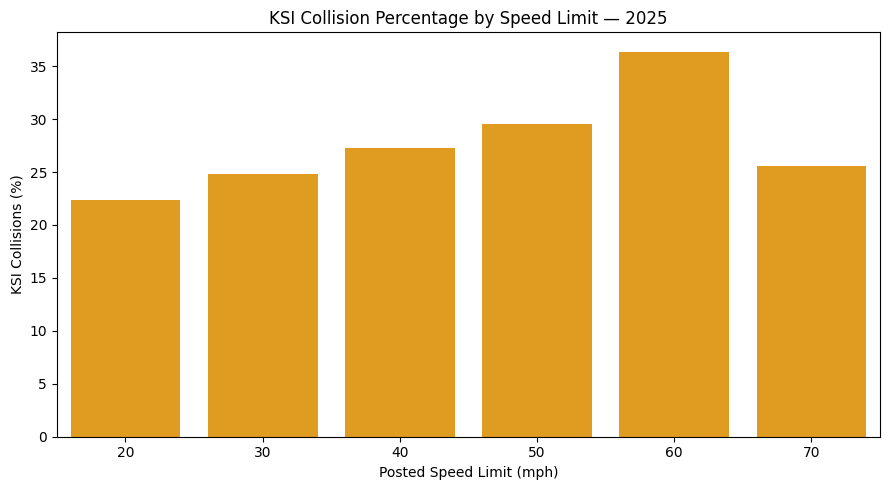

In [235]:
#Step:3- he KSI-percentage chart

plt.figure(figsize=(9,5))

sns.barplot(
    data= speed_plot_data,
    x= "speed_limit",
    y= "KSI_percentage",
    color= "orange"
)

plt.title("KSI Collision Percentage by Speed Limit — 2025")
plt.xlabel("Posted Speed Limit (mph)")
plt.ylabel ("KSI Collisions (%)")

plt.tight_layout()
plt.show()

*The highest number of recorded injury collisions occurred on 30 mph roads, whereas 60 mph roads had the highest proportion of collisions classified as fatal or serious (approximately 36.38%). This indicates an association between posted speed-limit category and collision severity in the dataset, but does not establish a causal relationship.*

**E2 — Correlation Heatmap**    
Relationships between numerical variables in the integrated dataset.

In [236]:
#Correlations

correlation_columns = [
    "number_of_vehicles",
    "number_of_casualties",
    "speed_limit",
    "collision_severity"
]

correlation_data = master_collision[
    correlation_columns
]

correlation_matrix = correlation_data.corr()

print(correlation_matrix.round(3))

                      number_of_vehicles  number_of_casualties  speed_limit  \
number_of_vehicles                 1.000                 0.160        0.109   
number_of_casualties               0.160                 1.000        0.152   
speed_limit                        0.109                 0.152        1.000   
collision_severity                 0.055                -0.080       -0.091   

                      collision_severity  
number_of_vehicles                 0.055  
number_of_casualties              -0.080  
speed_limit                       -0.091  
collision_severity                 1.000  


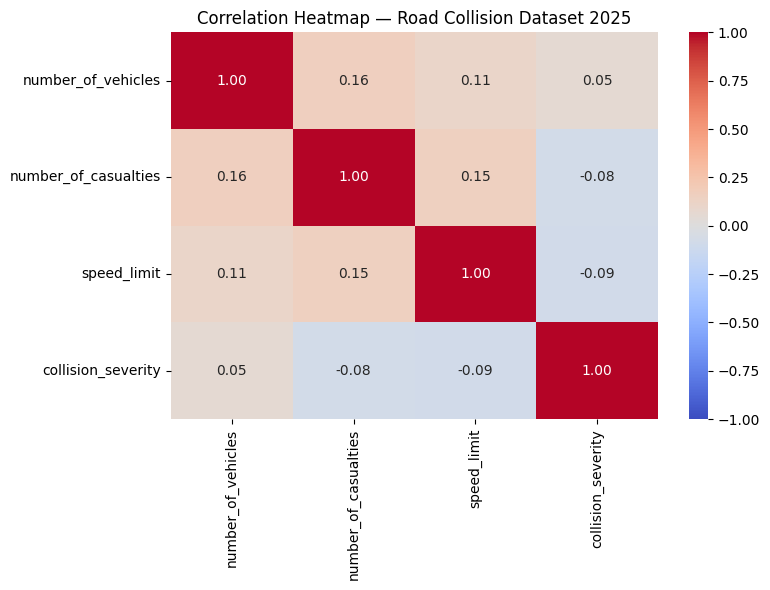

In [237]:
# E2.2 — Build the heatmap
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap — Road Collision Dataset 2025")
plt.tight_layout()
plt.show()

**Section E3: Severity and Casualty Visualisation**
Next task is to create:
1. A bar chart showing the counts of slight, serious and fatal collisions using master_collision.
2. A separate chart showing the distribution of casualty severity using casualty_test.

collision_severity
Fatal       1453
Serious    25191
Slight     74881
Name: count, dtype: int64


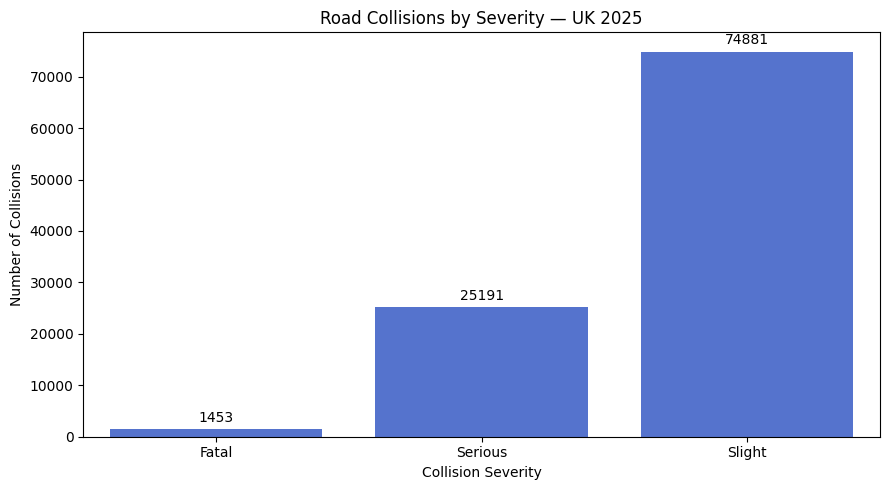

In [240]:
# E3.1 — Start with collision severity
severity_counts = (
    master_collision["collision_severity"]
    .map({1: "Fatal", 2: "Serious", 3: "Slight"})
    .value_counts()
    .reindex(["Fatal", "Serious", "Slight"])
)

print(severity_counts)

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Prepare the data
severity_data = pd.DataFrame({
    "collision_severity": ["Fatal", "Serious", "Slight"],
    "collision_count": [1453, 25191, 74881]
})

# Create the bar chart
plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=severity_data,
    x="collision_severity",
    y="collision_count",
    color="royalblue"
)

# Add title and labelled axes
plt.title("Road Collisions by Severity — UK 2025")
plt.xlabel("Collision Severity")
plt.ylabel("Number of Collisions")

# Display counts above each bar
for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=3)

plt.tight_layout()
plt.show()

casualty_severity
Fatal       1538
Serious    27758
Slight     98587
Name: count, dtype: int64
Serious casualties: 21.71%


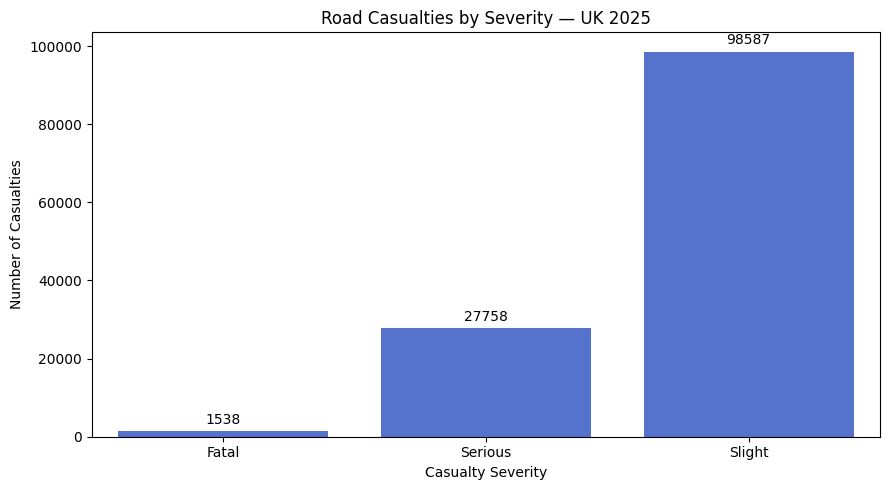

In [250]:
# E3.2 — Inspect the casualty severity codes

casualty_labels = {
    1: "Fatal",
    2: "Serious",
    3: "Slight"
}

casualty_counts = (
    casualty_test["casualty_severity"]
    .map(casualty_labels)
    .value_counts()
    .reindex(["Fatal", "Serious", "Slight"])
)

print(casualty_counts)

# Casulty percentage :
serious_percentage = (
    (casualty_test["casualty_severity"] == 2).mean() * 100
)

print(f"Serious casualties: {serious_percentage:.2f}%")

# Create Casualty Severity chart
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Prepare casualty severity data
casualty_data = pd.DataFrame({
    "casualty_severity": ["Fatal", "Serious", "Slight"],
    "casualty_count": [1538, 27758, 98587]
})

# Create the bar chart
plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=casualty_data,
    x="casualty_severity",
    y="casualty_count",
    color="royalblue"
)

# Add title and axis labels
plt.title("Road Casualties by Severity — UK 2025")
plt.xlabel("Casualty Severity")
plt.ylabel("Number of Casualties")

# Display counts above bars
for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=3)

plt.tight_layout()
plt.show()


**E4 — Time-Based Collision Analysis**     
Let's analyse when reported injury collisions occur during the day.

In [254]:
#E4.1 — Extract the collision hour
master_collision["collision_hour"] = pd.to_datetime(
    master_collision["time"],
    format="%H:%M",
    errors="coerce"
).dt.hour

print(
    master_collision[["time", "collision_hour"]].head(10)
)

print(
    "Missing or invalid times:",
    master_collision["collision_hour"].isna().sum()
)
hourly_collisions = (
    master_collision["collision_hour"]
    .value_counts()
    .sort_index()
    .reindex(range(24), fill_value=0)
)

print(hourly_collisions)

    time  collision_hour
0  15:00              15
1  09:35               9
2  18:18              18
3  16:30              16
4  07:45               7
5  12:11              12
6  11:45              11
7  17:31              17
8  16:00              16
9  16:40              16
Missing or invalid times: 0
collision_hour
0     1525
1     1032
2      789
3      651
4      634
5      952
6     1854
7     4248
8     6716
9     4493
10    4463
11    5069
12    5815
13    6148
14    6466
15    8381
16    8678
17    8877
18    6991
19    5356
20    4022
21    3368
22    2815
23    2182
Name: count, dtype: int64


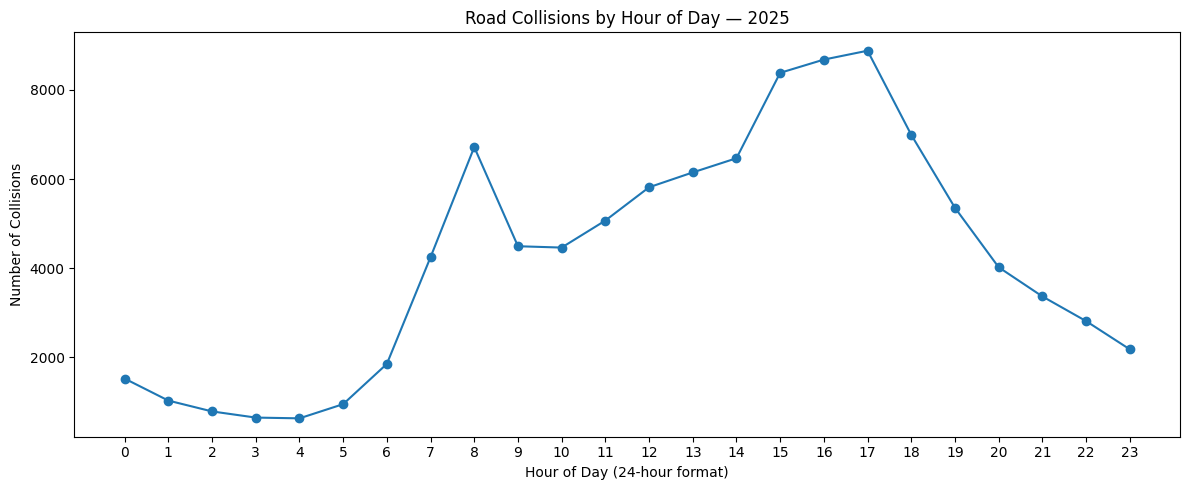

In [260]:
# E4.2 — Count collisions per hour
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 5))

plt.plot(
    hourly_collisions.index,
    hourly_collisions.values,
    marker = "o"
)

plt.title("Road Collisions by Hour of Day — 2025")
plt.xlabel("Hour of Day (24-hour format)")
plt.ylabel("Number of Collisions")

plt.xticks(range(24))
plt.tight_layout()
plt.show()

*Directly merging raw vehicle and casualty records on the collision reference can produce duplicate combinations because one collision may involve multiple vehicles and casualties. This can inflate the number of rows and cause double-counting. Aggregating each dataset to collision level before merging prevents this problem.*

#### Section F- Evidence-Based Findings

### Finding 1 — Slight collisions accounted for the majority of recorded collisions

Of the 101,525 recorded collisions, 74,881 (73.76%) were classified as slight, compared with 25,191 serious collisions (24.81%) and 1,453 fatal collisions (1.43%).

**Justification:** Although most recorded collisions were classified as slight, but a substantial number involved serious or fatal outcomes. Road safety analysis should therefore consider both overall collision frequency and severity.

### Finding 2 — More than one-quarter of collisions were classified as KSI

A total of 26,644 collisions were classified as fatal or serious, representing approximately 26.24% of the 101,525 recorded collisions.

**Justification:** The KSI proportion provides an important performance indicator for monitoring severe collision outcomes. It also helps to distinguish the proportion of the total volume of collisions from resulting in fatal or serious injuries.

### Finding 3 — The highest KSI percentage occurred on 60 mph roads

Among the six posted speed-limit categories, 60 mph roads had the highest proportion of KSI collisions at 36.38%, followed by 50 mph roads at 29.58%. The lowest proportion was recorded on 20 mph roads at 22.35%.

**Justification:** The differences justify further investigation into road design, urban or rural classification and traffic characteristics. They do not establish that the posted speed limit itself caused the differences in severity.
### Limitations

1. **No causal evidence:** Higher KSI percentages on 60 mph roads do not prove that speed limits caused more severe collisions.

2. **Lack of traffic-volume data:** Higher collision counts during peak hours may reflect heavier traffic rather than greater collision risk.

3. **Data quality:** Missing information, reporting errors or inconsistent records may affect the accuracy and reliability of the findings.

### Finding 4 — Serious casualties represented a substantial share of all casualties

Of the 127,883 recorded casualties, 27,758 (approximately 21.71%) were classified as seriously injured, while 1,538 (1.20%) were fatal casualties and 98,587 (77.09%) were slightly injured.

**Justification:** Casualty-level analysis measures the number of people affected, whereas collision-level analysis counts incidents. Both perspectives are necessary to understand the human impact of road collisions.

### Finding 5 — Fatal and serious casualties together represented nearly one-quarter of casualties in-accordance to time

### Executive Summary

This project analysed 101,525 recorded UK road collisions from the 2025 dataset using Python, Pandas and data visualisation techniques. The findings showed that 73.76% of collisions were classified as slight, while 26.24% were fatal or serious (KSI). Among the six speed-limit categories, 60 mph roads recorded the highest KSI proportion at 36.38%. The highest hourly collision count occurred between 17:00 and 17:59, with 8,877 recorded collisions.

However, these findings do not establish causation, and the absence of traffic-volume data limits conclusions about relative collision risk. Data quality and reporting limitations may also affect the results.

The analysis recommends further investigation of high-severity road environments, examination of peak-hour patterns using traffic-volume information, and continued improvement of data validation procedures to support evidence-based road safety decisions.